# Proof of concept: data analysis pipeline

This notebook generates a fake dataset to simulate the survey results. This is the code for data cleaning, interpretation, and visualization works before the real data surveying.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# generate data for 20 fake students (10 per group)
np.random.seed(42)

data = {
    'student_id': range(1, 21),
    'app_blocker_type': ['timer'] * 10 + ['pc_unlock'] * 10,
    'bypass_likelihood': np.zeros(20),
    'perceived_effort': np.zeros(20)
}

# simulate group A (timer/pop up): high bypass likelihood, low effort
data['bypass_likelihood'][0:10] = np.random.randint(4, 6, 10)
data['perceived_effort'][0:10] = np.random.randint(1, 3, 10)

# simulate group b (pc unlock): low bypass likelihood, high effort
data['bypass_likelihood'][10:20] = np.random.randint(1, 3, 10)
data['perceived_effort'][10:20] = np.random.randint(4, 6, 10)

df = pd.DataFrame(data)
df.to_csv('test_dataset.csv', index=False)

test dataset created and saved as csv.


## Data cleaning

We load the csv file and remove any incomplete rows. When the real data is added, we will also filter out responses completed too quickly.

In [5]:
df_clean = pd.read_csv('test_dataset.csv')
df_clean = df_clean.dropna()

print(df_clean.head(20))

    student_id app_blocker_type  bypass_likelihood  perceived_effort
0            1            timer                4.0               1.0
1            2            timer                5.0               1.0
2            3            timer                4.0               1.0
3            4            timer                4.0               1.0
4            5            timer                4.0               2.0
5            6            timer                5.0               1.0
6            7            timer                4.0               2.0
7            8            timer                4.0               2.0
8            9            timer                4.0               2.0
9           10            timer                5.0               1.0
10          11        pc_unlock                2.0               4.0
11          12        pc_unlock                1.0               4.0
12          13        pc_unlock                2.0               5.0
13          14        pc_unlock   

## Interpretation of results

We calculate the average score for both metrics grouping them by blocker type.

In [6]:
# group by the setup type and calculate the mean for the two metrics
summary = df_clean.groupby('app_blocker_type')[['bypass_likelihood', 'perceived_effort']].mean()

print(summary)

                  bypass_likelihood  perceived_effort
app_blocker_type                                     
pc_unlock                       1.9               4.4
timer                           4.3               1.4


## Visualization

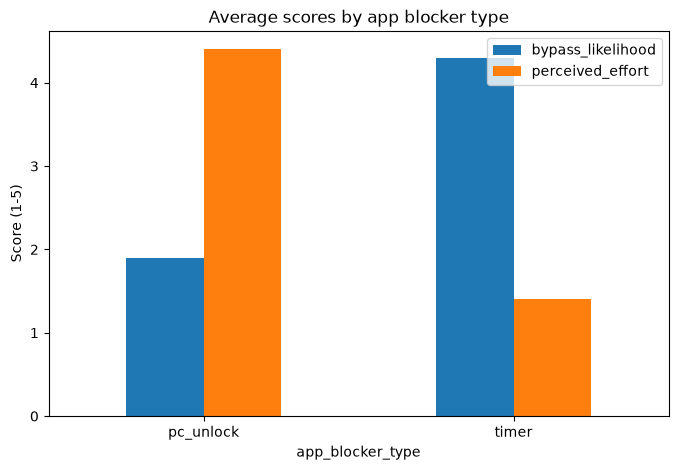

In [ ]:
summary.plot(kind='bar', figsize=(8, 5))

plt.title('Average scores by app blocker type')
plt.ylabel('Score (1-5)')
plt.xticks(rotation=0)
plt.show()